# `dilate`
Dilates the foreground of a boolean image with a round structuring element of radius `r`.

In [1]:
import matplotlib.pyplot as plt

import porespy as ps

ps.visualization.set_mpl_style()

The arguments and their defaults are:

In [2]:
import inspect

inspect.signature(ps.filters.dilate)

<Signature (im: numpy.ndarray[tuple[typing.Any, ...], numpy.dtype[~_ScalarT]], r: int, dt: numpy.ndarray[tuple[typing.Any, ...], numpy.dtype[~_ScalarT]] = None, method: str = 'dt', smooth: bool = True)>

## `im`
A boolean image with the foreground (the phase to be dilated) marked as `True`. Both 2D and 3D images are supported.

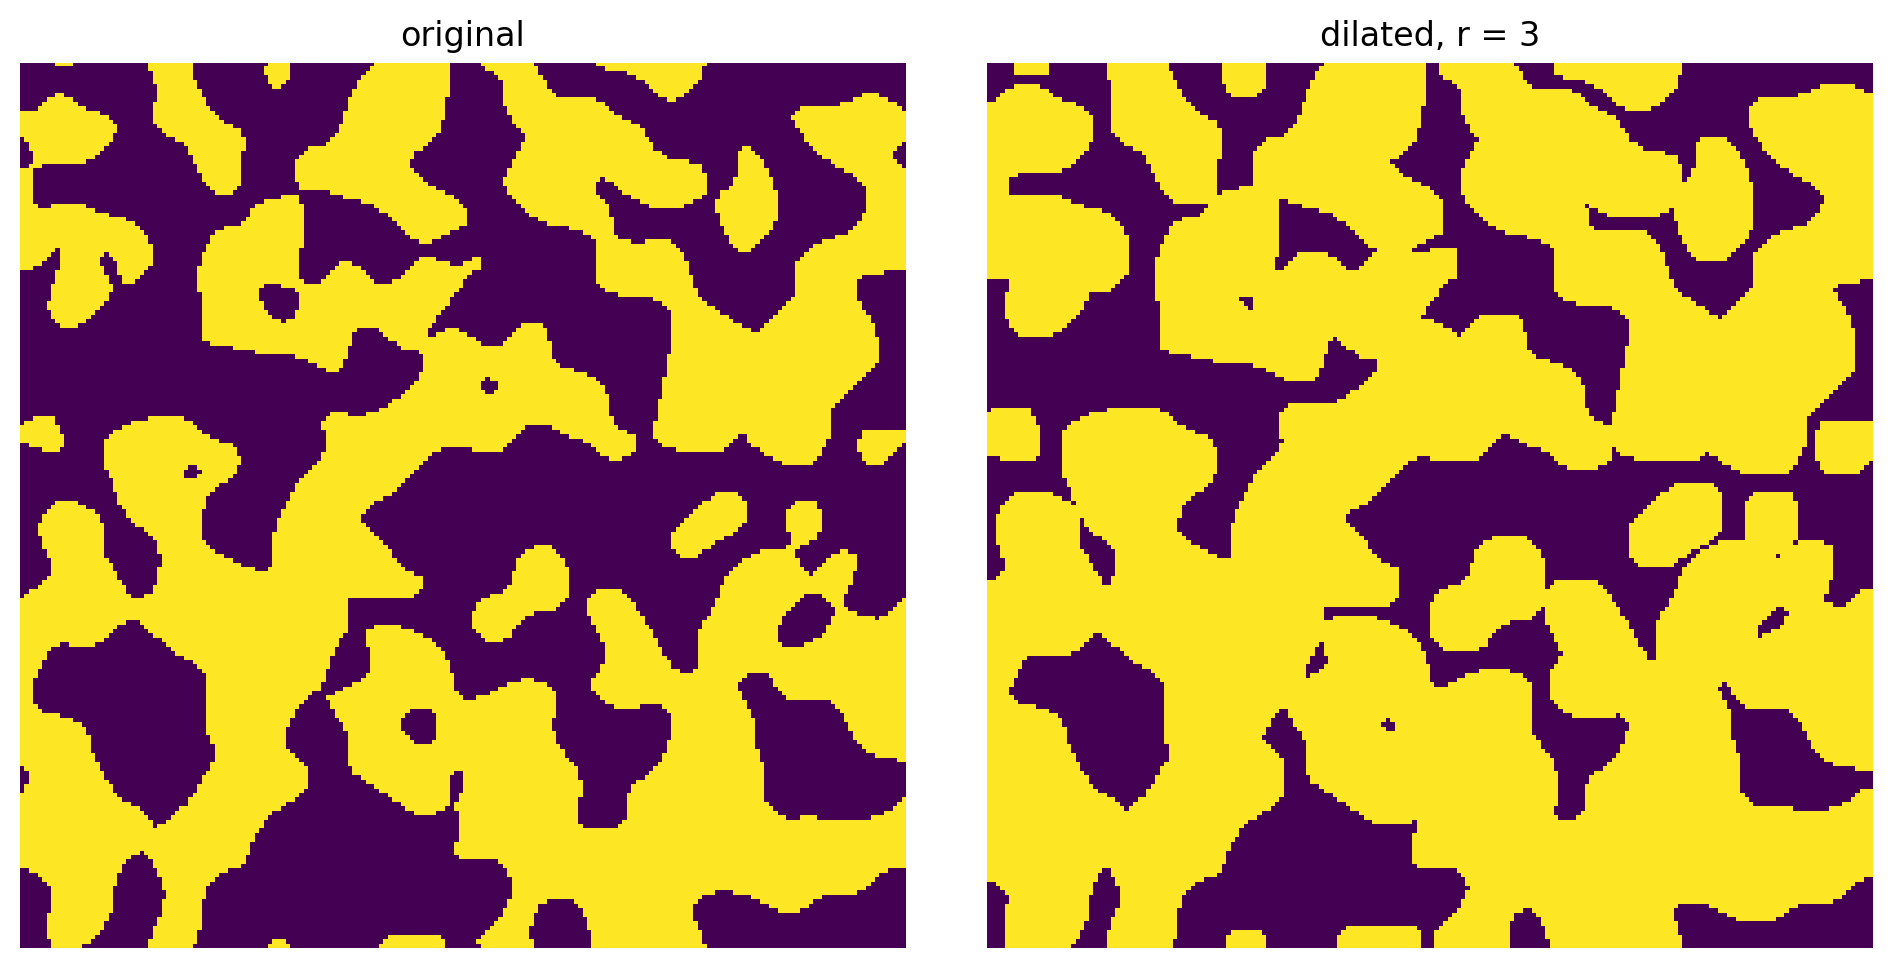

In [3]:
im = ps.generators.blobs(shape=[200, 200], porosity=0.5, seed=0)
dil = ps.filters.dilate(im=im, r=3)

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(im, origin='lower', interpolation='none')
ax[0].set_title('original')
ax[0].axis(False)
ax[1].imshow(dil, origin='lower', interpolation='none')
ax[1].set_title('dilated, r = 3')
ax[1].axis(False);

## `r`
Radius of the round structuring element, in voxels. Larger values dilate further.

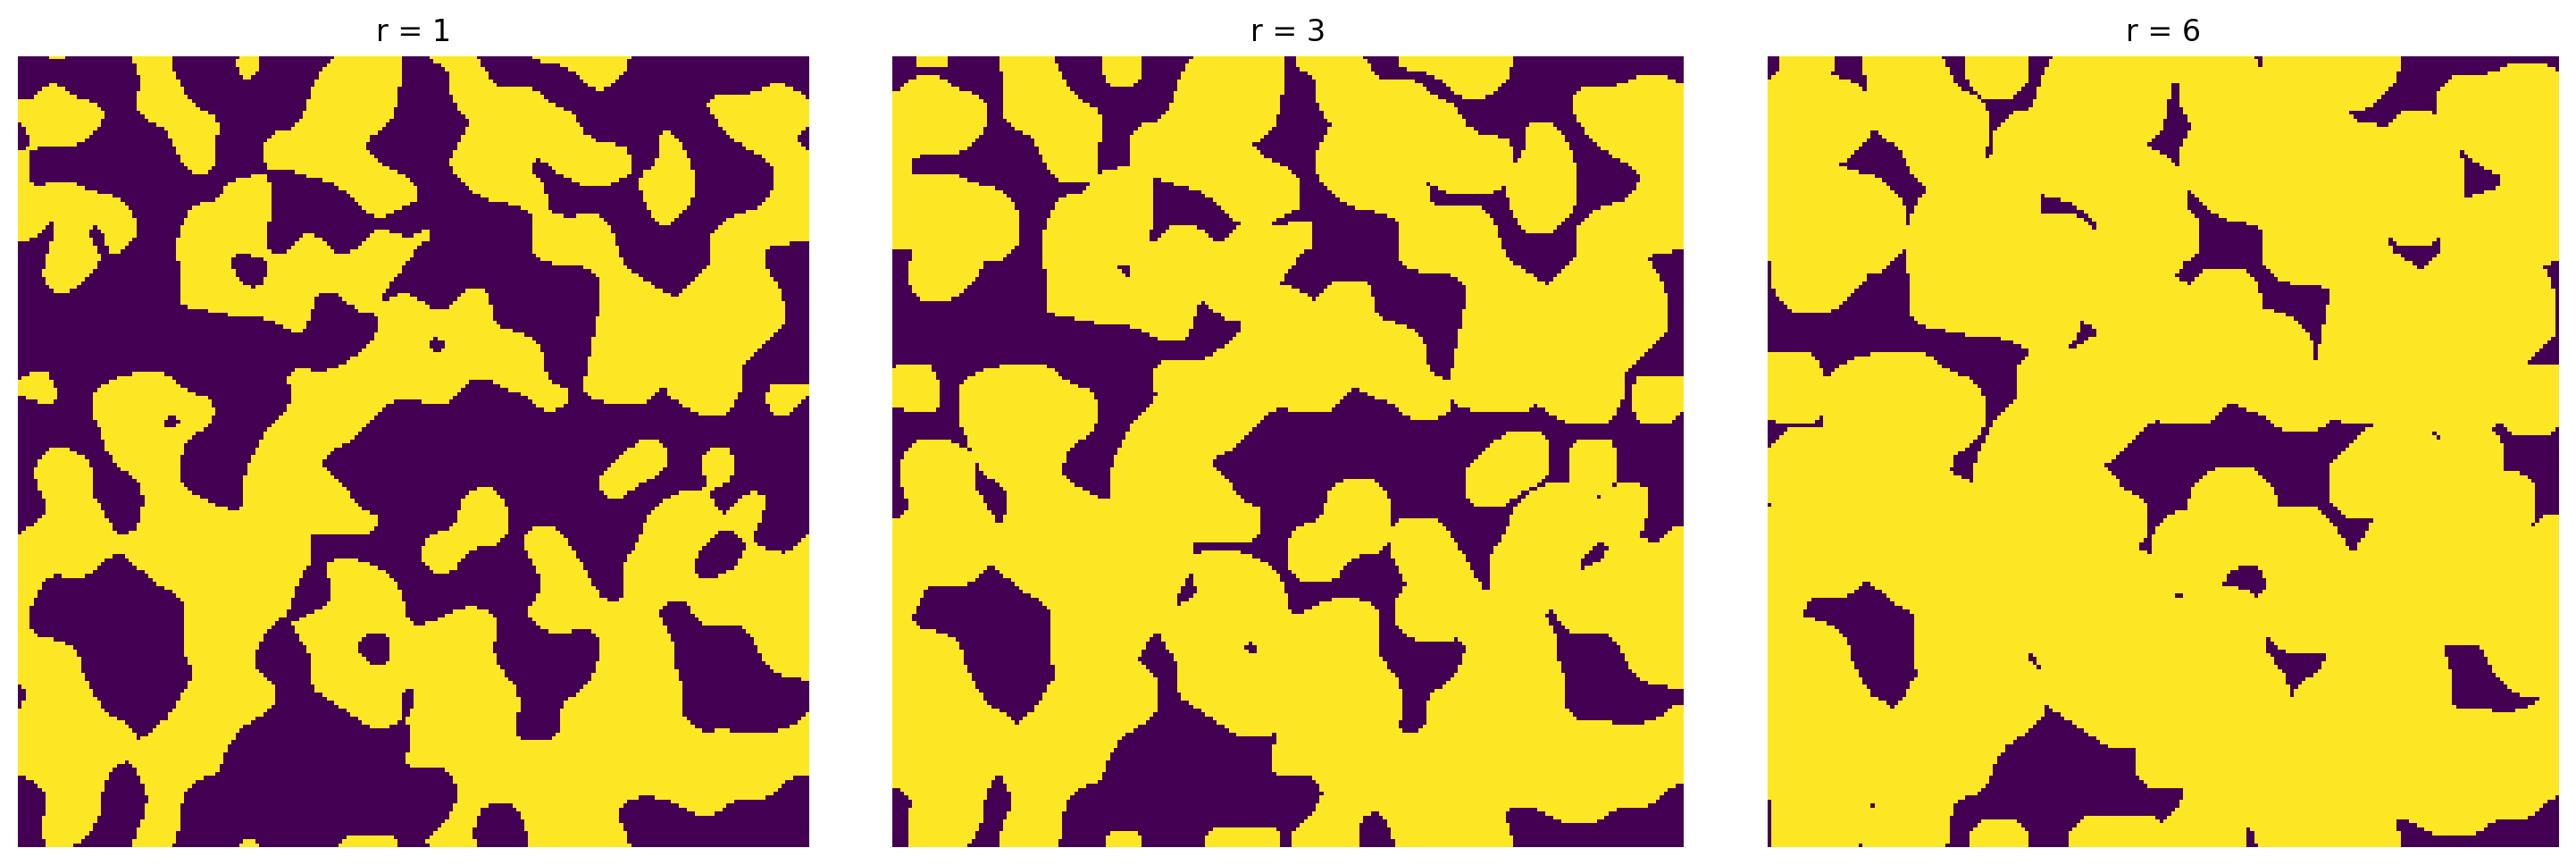

In [4]:
fig, ax = plt.subplots(1, 3, figsize=[15, 5])
for axis, r in zip(ax, [1, 3, 6]):
    dil = ps.filters.dilate(im=im, r=r)
    axis.imshow(dil, origin='lower', interpolation='none')
    axis.set_title(f'r = {r}')
    axis.axis(False)

## `method`
Three implementations are available:

- `'dt'` (default) uses the distance transform of the *background* to add voxels within `r` of the foreground.
- `'conv'` uses FFT-based convolution with a round structuring element.
- `'brute_force'` (alias `'bf'`) draws disks or spheres centered on foreground interface voxels to expand the foreground. It uses the shared optimized sphere-drawing routines without computing a distance transform.

The brute-force method supports 2D and 3D images and requires a nonnegative integer radius. It respects the `smooth` setting, and the `dt` argument is only used by the distance-transform method.

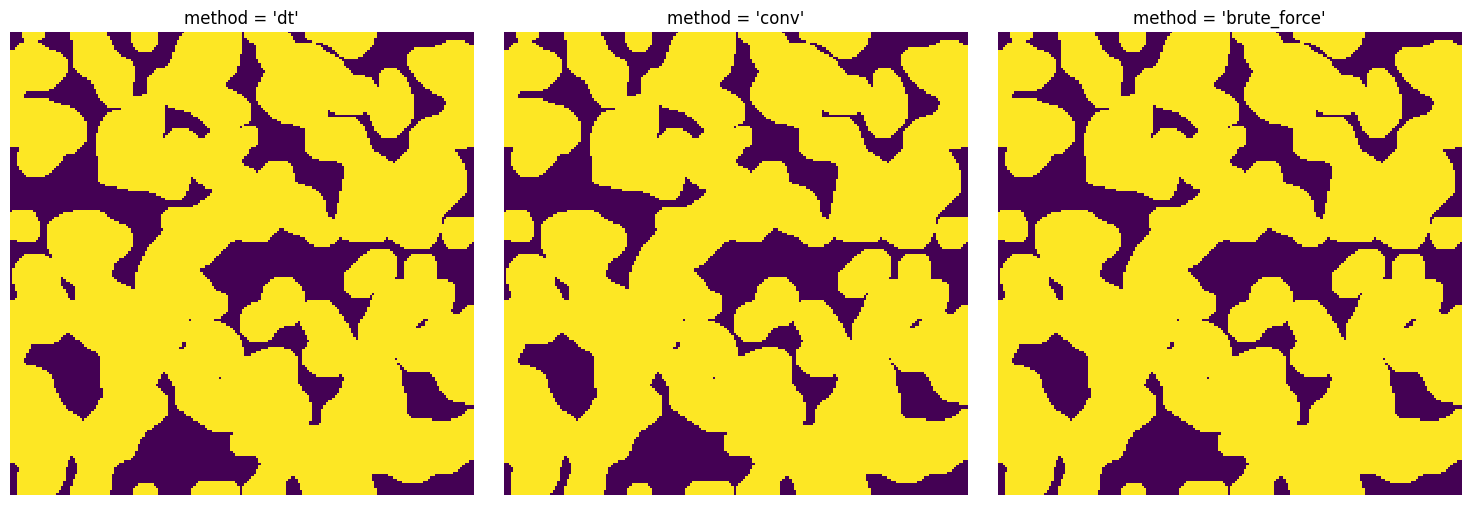

In [5]:
dil_dt = ps.filters.dilate(im=im, r=4, method='dt')
dil_conv = ps.filters.dilate(im=im, r=4, method='conv')
dil_bf = ps.filters.dilate(im=im, r=4, method='brute_force')

fig, ax = plt.subplots(1, 3, figsize=[15, 5])
for axis, result, method in zip(ax, [dil_dt, dil_conv, dil_bf],
                                ['dt', 'conv', 'brute_force']):
    axis.imshow(result, origin='lower', interpolation='none')
    axis.set_title(f"method = '{method}'")
    axis.axis(False)


## `smooth`
When `True` (default) a single-voxel protrusion on the face of the structuring element is removed, which gives visibly rounder boundaries. Set to `False` to keep the bare digital sphere.

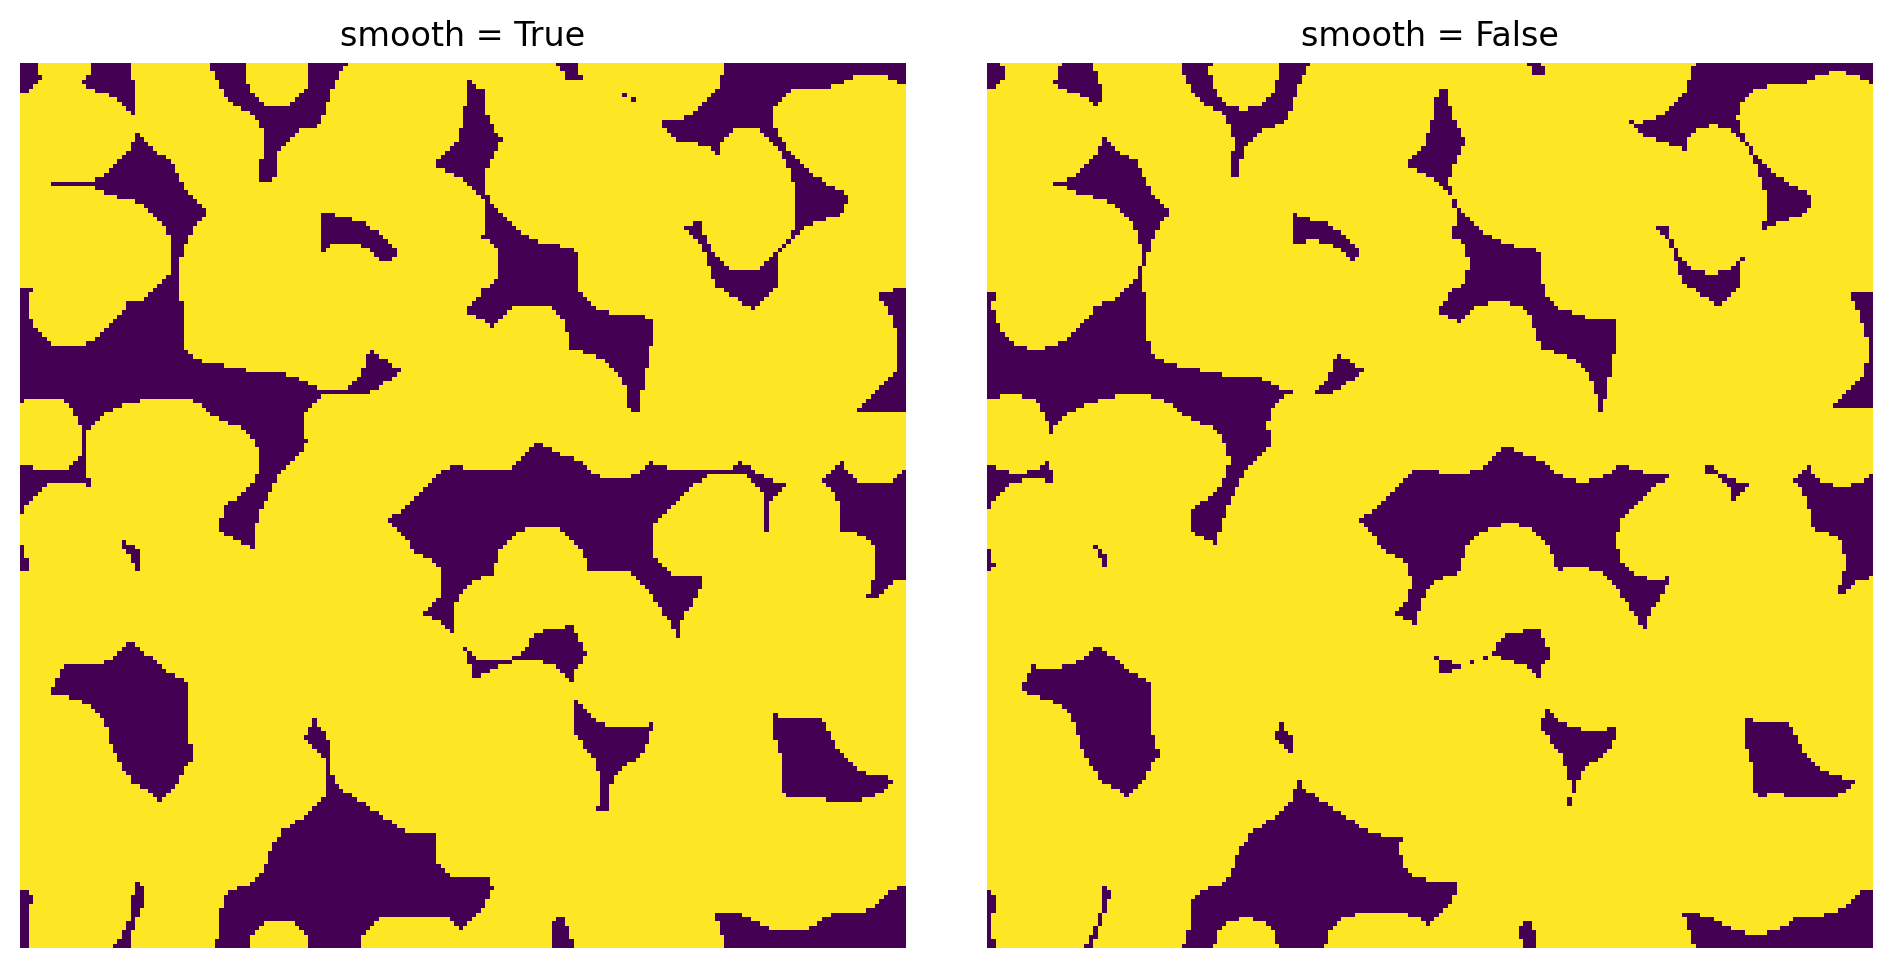

In [6]:
dil_smooth = ps.filters.dilate(im=im, r=5, smooth=True)
dil_rough = ps.filters.dilate(im=im, r=5, smooth=False)

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(dil_smooth, origin='lower', interpolation='none')
ax[0].set_title('smooth = True')
ax[0].axis(False)
ax[1].imshow(dil_rough, origin='lower', interpolation='none')
ax[1].set_title('smooth = False')
ax[1].axis(False);

## `dt`
If the distance transform of the *background* is already available it can be passed in to avoid recomputing it. This argument only matters when `method='dt'`.

In [7]:
from porespy.tools import get_edt

dt_bg = get_edt()(~im)
dil = ps.filters.dilate(im=im, r=4, dt=dt_bg)